# Real networks: repeated active queries and one-query diagnostics

Read-only analysis of `results/overnight_v2`; original pilot results remain in `results/active_test`. Collection is run in the terminal, not this notebook.

On three Enron pairs, FAQ and GOAT start with five verified seeds from top degree or randomized distinguishing. Four policies share exactly the same initial matching and query one vertex per round up to 30: random continuation, distinguishing continuation, ensemble uncertainty, and uncertainty multiplied by the sum of neighboring vertices' uncertainty. Each starting rule has ten repeated trajectories across five held-out test partitions.

Uncertainty is one minus the modal partner frequency in ten fresh feasible matchings: one barycentric initialization and nine with perturbation weight 0.2. It is an optimization-ensemble diagnostic, not a calibrated posterior or an exact reproduction of TopMatchings/GibbsMatchings. The corrected previous assignment competes with fresh runs by edge objective, equally for every policy. Uncertainty always comes from fresh runs under all current verified answers. Tied optimal soft projections are accepted.


In [6]:
from pathlib import Path
import sys
REPO = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'experiment_common').is_dir())
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))
import matplotlib.pyplot as plt
from IPython.display import display
from real_data_experiments import strategy_and_active_v2 as O, strategy_and_active_v2_analysis as N
from real_data_experiments import strategy_comparison as C
OUTPUT = O.OUTPUT_DIR
METRIC = 'accuracy_test'  # also 'accuracy_nonseed' or 'accuracy_all'
plt.rcParams.update({'font.size': 9, 'figure.dpi': 110})
O.status(OUTPUT)


Results: /Users/langsong/Desktop/Seeded-Graph-Matching/real_data_experiments/results/overnight_v2
Completed tasks: {'strategy': 4068, 'diagnostic': 94, 'active': 120, 'pilot': 36}
Unresolved errors: 0
{
  "state": "complete",
  "elapsed_hours": 5.571521602881945,
  "remaining_tasks": 0,
  "calibration_complete": true,
  "errors": 0,
  "updated_at": "2026-11-18T07:56:12-05:00"
}



## 1. Completion and paired comparisons

Only budgets at which all four policies have finished for a repetition enter comparisons. Means first average repetitions within a test partition, then weight partitions equally. Bands describe observed trajectory variability, not confidence intervals across independent graphs. All methods exclude the same held-out vertices from queries.


In [7]:
active = N.read_active(OUTPUT)
summary = N.active_summary(active, METRIC)
if summary.empty:
    print('No balanced active comparison yet; diagnostics may still be available below.')
else:
    last = summary.groupby(['case', 'algorithm', 'base']).budget.transform('max')
    endpoint = summary[summary.budget == last]
    display(endpoint.pivot(index=['case', 'algorithm', 'base', 'budget'],
                           columns='policy', values='mean').round(3))
    print('Endpoint repetition counts range:', int(endpoint.repetitions.min()),
          'to', int(endpoint.repetitions.max()))


policy                                         random  structural  \
case          algorithm base           budget                       
enron_130_132 faq       distinguishing 30       0.639       0.646   
                        top_degree     30       0.668       0.679   
              goat      distinguishing 30       0.639       0.657   
                        top_degree     30       0.636       0.664   
enron_145_147 faq       distinguishing 30       0.533       0.529   
                        top_degree     30       0.552       0.571   
              goat      distinguishing 30       0.514       0.557   
                        top_degree     30       0.543       0.576   
enron_160_162 faq       distinguishing 30       0.737       0.763   
                        top_degree     30       0.747       0.774   
              goat      distinguishing 30       0.789       0.737   
                        top_degree     30       0.789       0.758   

policy                                         uncertainty  uncertainty_impact  
case          algorithm base           budget                                   
enron_130_132 faq       distinguishing 30            0.600               0.736  
                        top_degree     30            0.604               0.686  
              goat      distinguishing 30            0.629               0.650  
                        top_degree     30            0.654               0.643  
enron_145_147 faq       distinguishing 30            0.543               0.610  
                        top_degree     30            0.581               0.586  
              goat      distinguishing 30            0.629               0.629  
                        top_degree     30            0.595               0.657  
enron_160_162 faq       distinguishing 30            0.789               0.779  
                        top_degree     30            0.842               0.758  
              goat      distinguishing 30            0.832               0.732  
                        top_degree     30            0.811               0.721

Endpoint repetition counts range: 10 to 10


## 2. Accuracy versus verified seed budget

The default y-axis is fixed-test accuracy, so directly correcting a purchased vertex does not automatically improve this metric. Use `accuracy_all` for the total number of identities recovered, including purchased answers. The active policies use equal solver effort; comparing their curves directly with the separate two-run static experiment would mix different solver budgets.


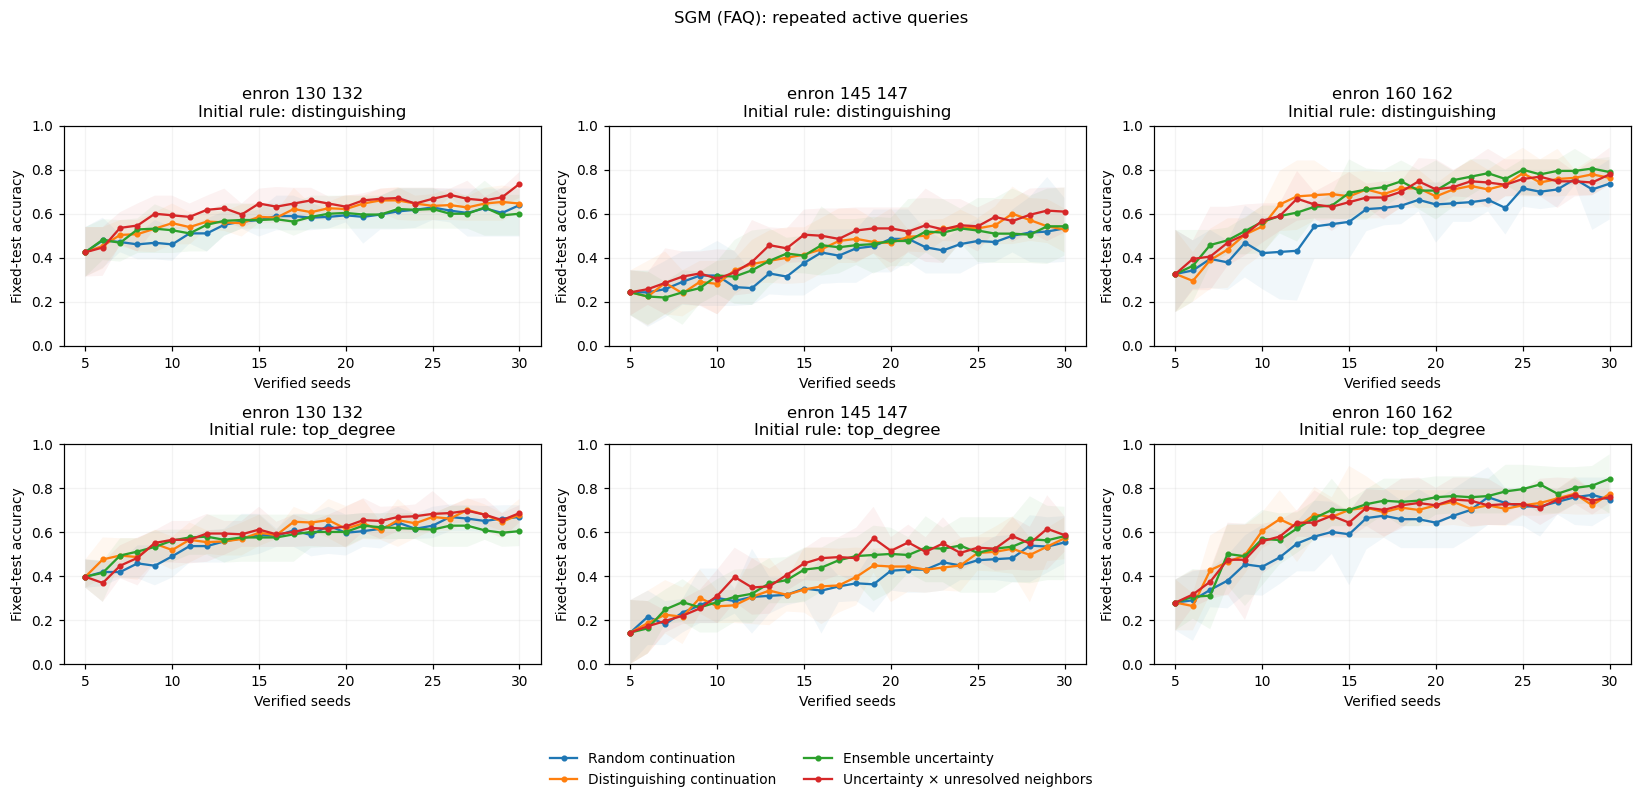

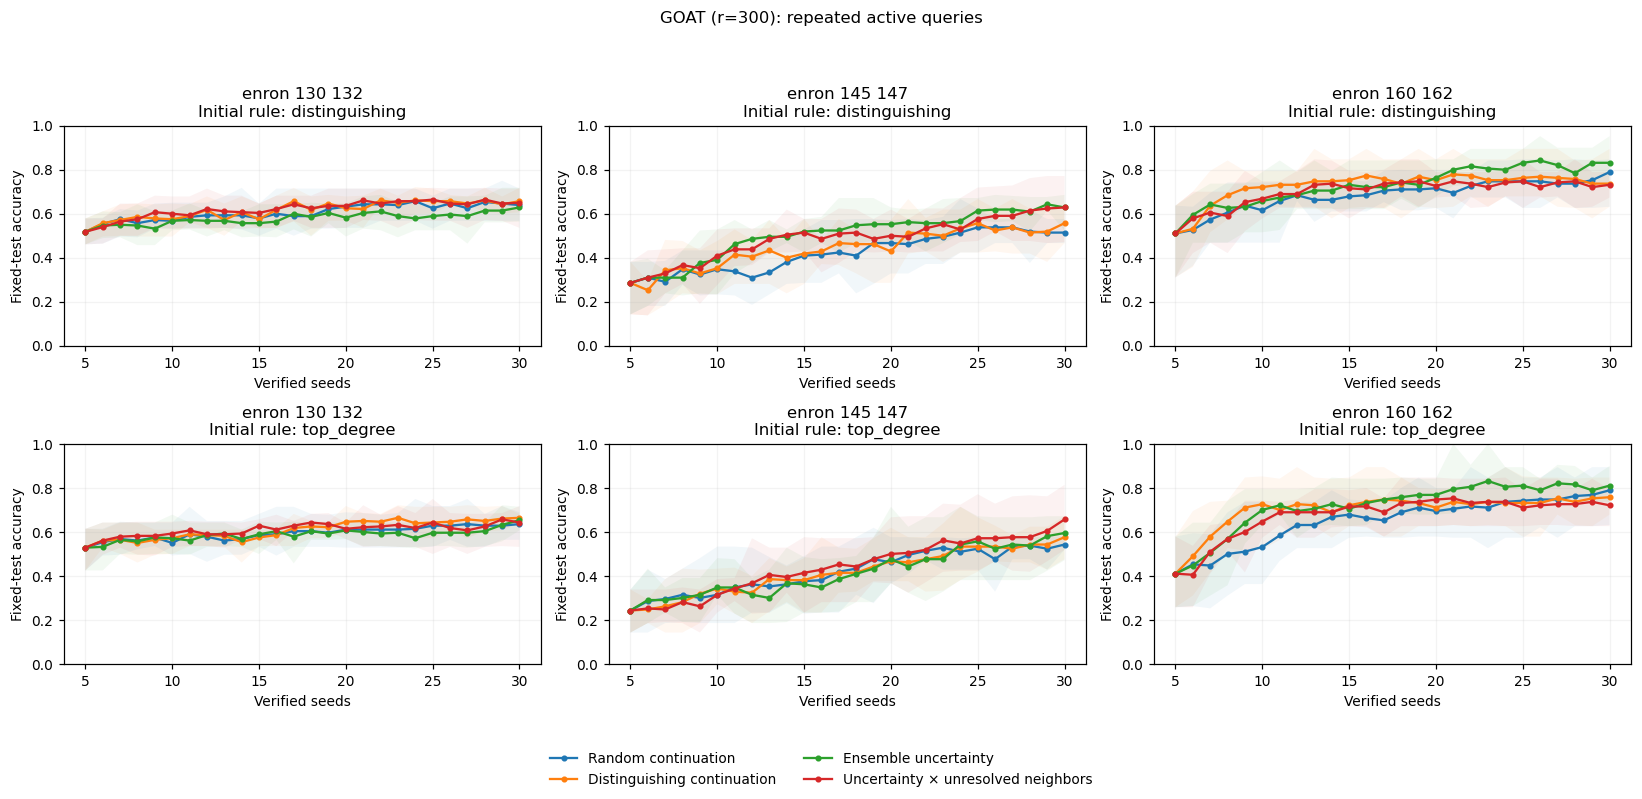

In [8]:
if not summary.empty:
    for algorithm in ('faq', 'goat'):
        if algorithm in set(summary.algorithm):
            fig = N.plot_active(summary, algorithm, OUTPUT, METRIC)
            plt.show()
            plt.close(fig)


## 3. Do useful queries look uncertain?

The diagnostic branches from a fixed initial state and separately reveals each candidate's true partner. Each branch uses three barycentric solver runs, paired with three fresh no-query baseline runs using the same random seeds. The initial uncertainty ensemble is separate. This compares one additional verified seed at equal solver effort.

Small-pair states test all eligible candidates at initial budgets 5, 10, and 20. Wikipedia tests 16 candidates mixing random, uncertain, uncertainty-impact, and distinguishing choices, at budgets 10 and 20 (FAQ only). Candidate selection does not use unrevealed truth. Only fully evaluated candidate lists enter the table.

Spearman correlations measure whether a candidate score ranks observed fixed-test gains. The best observed gain uses ground truth and is an optimistic diagnostic reference, not a deployable method or a validated upper bound. The mean candidate gain on Wikipedia is for its deliberately mixed shortlist, not a uniform-random estimate. A flat single-query landscape does not exclude complementary multi-seed effects.


In [9]:
diagnostics = N.read_diagnostics(OUTPUT)
diagnostic_table = N.diagnostic_summary(diagnostics)
if diagnostics.empty:
    print('No diagnostic outcomes saved yet.')
else:
    print('Saved candidate outcomes:', len(diagnostics),
          '| outcomes in complete states:', int(diagnostics.state_complete.sum()))
    display(diagnostic_table.round(3))


Saved candidate outcomes: 7204 | outcomes in complete states: 7204


states  candidates_per_state  mean_gain  \
case          algorithm budget                                            
enron_130_132 faq       5            5                 108.0      0.008   
                        10           5                 103.0      0.045   
                        20           5                  93.0      0.009   
              goat      5            5                 108.0      0.028   
                        10           5                 103.0      0.038   
                        20           5                  93.0     -0.007   
enron_145_147 faq       5            5                  78.0      0.044   
                        10           5                  73.0     -0.004   
                        20           5                  63.0     -0.013   
              goat      5            5                  78.0      0.029   
                        10           5                  73.0      0.016   
                        20           5                  63.0      0.013   
enron_160_162 faq       5            5                  72.0      0.061   
                        10           5                  67.0     -0.005   
                        20           5                  57.0      0.017   
              goat      5            5                  72.0      0.024   
                        10           5                  67.0      0.017   
                        20           5                  57.0      0.009   
wikipedia     faq       10           2                  16.0      0.045   
                        20           2                  16.0      0.001   

                                best_observed_gain  rho_uncertainty  \
case          algorithm budget                                        
enron_130_132 faq       5                    0.157           -0.113   
                        10                   0.186           -0.047   
                        20                   0.100           -0.043   
              goat      5                    0.138           -0.103   
                        10                   0.148            0.017   
                        20                   0.055            0.089   
enron_145_147 faq       5                    0.200           -0.035   
                        10                   0.127            0.091   
                        20                   0.108           -0.011   
              goat      5                    0.229            0.064   
                        10                   0.162            0.180   
                        20                   0.117            0.045   
enron_160_162 faq       5                    0.232            0.112   
                        10                   0.144            0.096   
                        20                   0.119            0.083   
              goat      5                    0.316            0.133   
                        10                   0.154           -0.010   
                        20                   0.091            0.188   
wikipedia     faq       10                   0.240            0.145   
                        20                   0.042           -0.191   

                                rho_impact  rho_degree  rho_distinguishing  
case          algorithm budget                                              
enron_130_132 faq       5            0.125       0.153               0.151  
                        10           0.188       0.120               0.116  
                        20           0.027       0.017               0.013  
              goat      5            0.104       0.147               0.121  
                        10           0.177       0.131               0.047  
                        20          -0.002      -0.031               0.045  
enron_145_147 faq       5            0.061       0.134               0.205  
                        10           0.052      -0.052               0.029  
                        20           0.125      

## 4. Reading the outcome

High error-detection AUC or a high query hit rate can coexist with little gain on other vertices. Conversely, a currently correct match may still be useful to verify as a hard constraint. Low AUC rejects that particular error-ranking signal, not all active selection.

Check whether active policies repeatedly beat both random and structural continuation, whether the initial seed rule changes the outcome, and whether uncertainty or structural contribution predicts measured query benefits. Edge-objective safeguards do not guarantee improved identity accuracy. Graph pairs remain fixed throughout these repetitions.


In [10]:
N.export(OUTPUT, active_rounds=active, active_summary=summary,
         query_diagnostics=diagnostics, query_diagnostic_summary=diagnostic_table.reset_index())
print('CSV summaries and figures:', OUTPUT / 'analysis')


CSV summaries and figures: /Users/langsong/Desktop/Seeded-Graph-Matching/real_data_experiments/results/overnight_v2/analysis
